This code contain complete overvieew of Music and distance estimation algorithms implementation with pre- and post-processing of data and it visualization

*Signal pre-processing 1*
✅ What is DC Offset?
📡 In RF signals:
IQ data is a complex signal:

s[n]=I[n]+j⋅Q[n]

Ideally, the average of both I and Q components is zero over time:

mean(I)=0,mean(Q)=0

But in real-world hardware like SDRs (e.g., KrakenSDR, RTL-SDR), imperfections cause non-zero mean values — this is the DC offset.

⚙️ Why does DC Offset Happen?
Common causes:
Hardware imperfections in the ADC (Analog-to-Digital Converter)

Local oscillator leakage

- I/Q imbalance

- Uncalibrated front-end

- Signal reflections (in poor setups)

It appears as a spike at 0 Hz in the frequency domain. This pollutes your spectral or phase analysis (like MUSIC).

🧮 How do we fix it?
You simply subtract the mean from the signal in vector form.

This re-centers the cloud of IQ points around the origin (0, 0).

🧪 Let's Simulate and Visualize It
We'll create:

- A synthetic complex sinusoid signal with DC offset

- Apply DC offset removal

- Visualize before and after

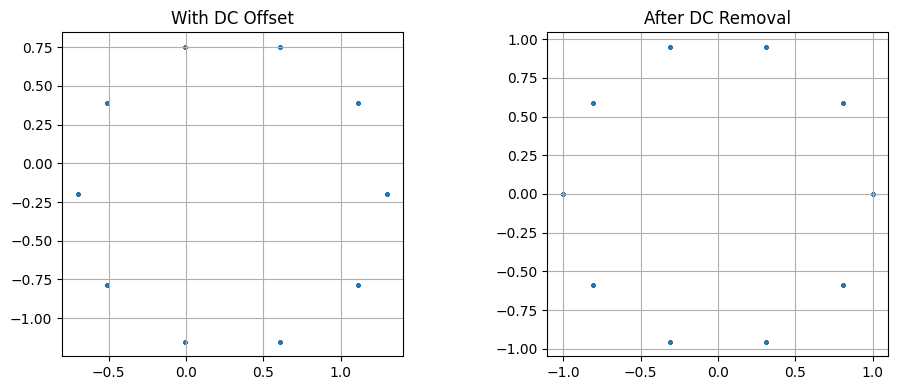

In [198]:
import numpy as np
import matplotlib.pyplot as plt


def generate_test_iq_with_dc_offset(
    num_samples=1024, offset_real=0.3, offset_imag=-0.2, freq=0.1
):
    """
    Generate synthetic IQ signal with DC offset.
    """
    t = np.arange(num_samples)
    iq_signal = np.exp(2j * np.pi * freq * t)  # pure tone
    iq_signal += offset_real + 1j * offset_imag  # Add DC offset
    return iq_signal


def remove_dc_offset(signal):
    """
    Removes the mean (DC component) from a complex IQ signal.
    """
    return signal - np.mean(signal)


def visualize_before_after(original, cleaned):
    """
    Plots I/Q scatter before and after DC removal.
    """
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].scatter(np.real(original), np.imag(original), s=2)
    ax[0].set_title("With DC Offset")
    ax[0].grid(True)
    ax[0].set_aspect("equal")

    ax[1].scatter(np.real(cleaned), np.imag(cleaned), s=2)
    ax[1].set_title("After DC Removal")
    ax[1].grid(True)
    ax[1].set_aspect("equal")

    plt.tight_layout()
    plt.show()


# Generate test data
iq_with_offset = generate_test_iq_with_dc_offset()
iq_centered = remove_dc_offset(iq_with_offset)

# Visualize
visualize_before_after(iq_with_offset, iq_centered)

Windowing

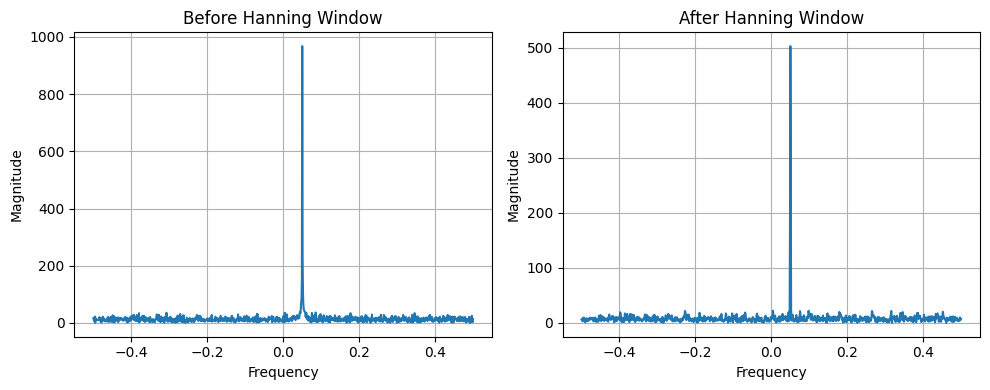

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def generate_test_tone(num_samples=1024, freq=0.05, noise_power=0.1):
    """
    Generate a test complex tone with noise.
    """
    t = np.arange(num_samples)
    tone = np.exp(2j * np.pi * freq * t)
    noise = (
        np.random.randn(num_samples) + 1j * np.random.randn(num_samples)
    ) * np.sqrt(noise_power)
    return tone + noise


def apply_hanning_window(signal):
    """
    Apply Hann window to complex signal.
    """
    hann = np.hanning(len(signal))
    return signal * hann


def plot_fft(signal, sample_rate=1.0, title=""):
    """
    Plot magnitude spectrum of signal.
    """
    N = len(signal)
    freqs = np.fft.fftfreq(N, d=1 / sample_rate)
    spectrum = np.fft.fft(signal)

    plt.plot(np.fft.fftshift(freqs), np.fft.fftshift(np.abs(spectrum)))
    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel("Magnitude")
    plt.grid(True)


# Generate signal
signal = generate_test_tone()
windowed_signal = apply_hanning_window(signal)

# Plot FFTs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plot_fft(signal, title="Before Hanning Window")

plt.subplot(1, 2, 2)
plot_fft(windowed_signal, title="After Hanning Window")
plt.tight_layout()
plt.show()

*📡 What is Band-Pass Filtering?
✅ In simple words:
A band-pass filter allows only a specific range of frequencies to pass through and removes (attenuates) all others.

Think of it like a radio tuner:

You only want to “hear” a specific frequency band (like 95–105 MHz)

Band-pass filtering helps you isolate useful signals and remove noise or interference from outside your range.

🧠 Why is it needed in IQ signal processing?
When you're analyzing a signal with MUSIC or any other RF method, you often:

Know approximately what frequency your signal is at

Want to remove irrelevant signals, thermal noise, or DC offsets

So, band-pass filtering cleans the signal before processing — just like noise-canceling headphones removing background chatter.
🎯 What is Windowing? (e.g., Hanning Window)
📡 Context
In signal processing, when we work with finite-length signals (like a few thousand IQ samples), it’s as if we’re multiplying the infinite signal by a rectangular window — this causes spectral leakage in the frequency domain.

❓ What's Spectral Leakage?
Let’s say you want to analyze a single frequency tone using FFT. If the signal doesn't perfectly fit inside your sample window (i.e., not an integer number of cycles), energy from that frequency “leaks” into nearby frequencies. This causes blurry peaks or side lobes.

🧰 Solution: Apply a Window Function
Instead of just chopping the signal with a rectangle, you taper the edges with a function like the Hanning window (or Hann window). This smooths the transitions at the edges.

📐 What is the Hanning (Hann) Window?
The Hann window is defined as:

w[n] = 0.5 (1−cos (2πn/N−1) ), 0 ≤ n < N

It's a smooth bell-shaped curve (in time) used to reduce spectral leakage in the frequency domain.

🧪 Let’s Simulate and Visualize It
We’ll:
- Generate a noisy sine wave
- Apply a Hanning window
- Compare FFT before and after

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter, freqz


def generate_test_iq_signal(freq1=50, freq2=200, fs=1000, N=1024):
    """
    Generates a test IQ signal with two frequencies.
    """
    t = np.arange(N) / fs
    signal = np.exp(1j * 2 * np.pi * freq1 * t) + 0.5 * np.exp(
        1j * 2 * np.pi * freq2 * t
    )
    return signal


def butter_bandpass(lowcut, highcut, fs, order=5):
    """
    Create Butterworth band-pass filter coefficients.
    """
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype="band")
    return b, a


def apply_bandpass_filter(iq_signal, lowcut, highcut, fs, order=5):
    """
    Apply band-pass filter to IQ signal (real + imag separately).
    """
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    filtered_real = lfilter(b, a, iq_signal.real)
    filtered_imag = lfilter(b, a, iq_signal.imag)
    return filtered_real + 1j * filtered_imag


# Create test signal
fs = 1000  # Sampling rate
iq = generate_test_iq_signal(freq1=50, freq2=200, fs=fs)

# Apply band-pass filter to isolate 40–60 Hz range
filtered_iq = apply_bandpass_filter(iq, lowcut=40, highcut=60, fs=fs)


# FFT for visualization
def plot_fft(signal, fs, title):
    N = len(signal)
    freqs = np.fft.fftfreq(N, d=1 / fs)
    fft_vals = np.abs(np.fft.fft(signal))

    plt.plot(freqs[: N // 2], fft_vals[: N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_fft(iq, fs, "Original Signal (Contains 50 Hz + 200 Hz)")

plt.subplot(1, 2, 2)
plot_fft(filtered_iq, fs, "Filtered Signal (Only 50 Hz Remains)")

plt.tight_layout()
plt.show()

*Music algorithm*
🎯 What is the MUSIC Algorithm?
MUSIC estimates the direction(s) from which signals are arriving using signals from multiple antennas.

Imagine:

You have 5 antennas arranged in a row (uniform linear array).

You receive the same signal with a tiny phase shift between antennas, depending on the angle it came from.

MUSIC uses this phase difference across antennas to estimate angles of arrival (AoA).

🧠 Mathematical Intuition (lightly simplified)
Setup:
Let:

M: number of antennas (e.g., 5)

N: number of samples collected

X: M×N data matrix (rows = antennas, columns = time samples)

Step-by-step:
Covariance matrix

R= 1/N * XX^H
 
(This captures how signals across antennas are correlated.)

Eigen decomposition of 

R=UΛU^H
 
Split eigenvectors into:

- Signal subspace: associated with largest eigenvalues (how many sources you expect)
- Noise subspace: the rest

Steering vector 

a(θ): predicts phase shifts for signal from angle

For linear array with spacing 

​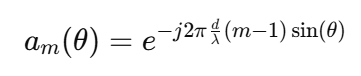
 
where:

λ: wavelength

m: antenna index (1 to M)

MUSIC Spectrum:
The key idea is that the steering vector for the correct angle is orthogonal to noise subspace.
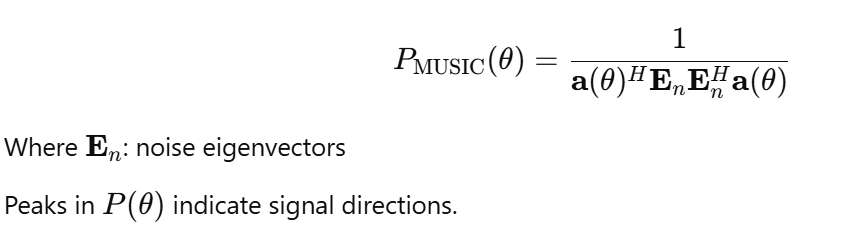

In [199]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import eig, svd, norm


def compute_covariance_matrix(iq_matrix):
    """
    Computes the covariance matrix from the MxN IQ data matrix.
    """
    return (iq_matrix @ iq_matrix.conj().T) / iq_matrix.shape[1]


def steering_vector(angle_rad, num_antennas, spacing, wavelength):
    """
    Constructs the steering vector for a given angle.
    """
    k = 2 * np.pi / wavelength
    positions = np.arange(num_antennas) * spacing
    return np.exp(-1j * k * positions * np.sin(angle_rad))


def music_spectrum(
    iq_matrix, num_sources, spacing, wavelength, angle_scan=np.linspace(-90, 90, 1801)
):
    """
    Computes the MUSIC spectrum over a range of angles.
    """
    R = compute_covariance_matrix(iq_matrix)
    eigvals, eigvecs = eig(R)

    # Sort eigenvalues descending
    idx = eigvals.argsort()[::-1]
    eigvecs = eigvecs[:, idx]

    # Noise subspace
    En = eigvecs[:, num_sources:]

    P_music = []
    for angle_deg in angle_scan:
        angle_rad = np.deg2rad(angle_deg)
        a = steering_vector(angle_rad, iq_matrix.shape[0], spacing, wavelength)
        music_val = 1 / np.abs(a.conj().T @ En @ En.conj().T @ a)
        P_music.append(music_val)

    return angle_scan, 10 * np.log10(np.real(P_music))  # dB scale

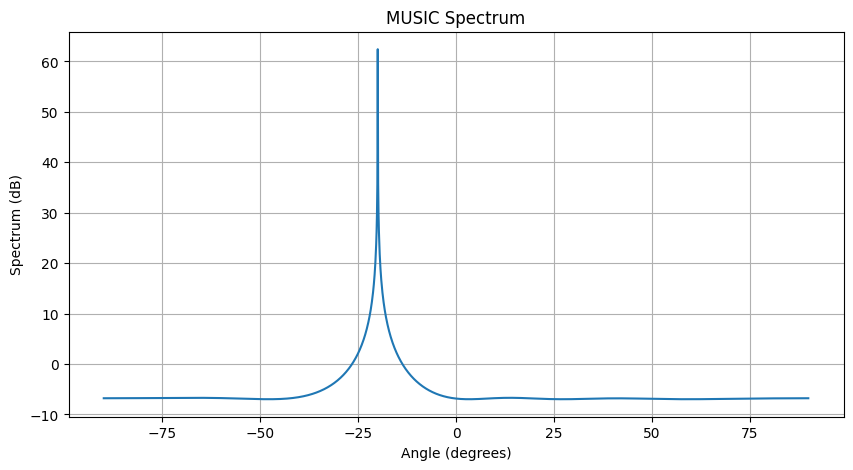

In [ ]:
def simulate_signals(
    num_antennas=5, num_samples=1024, signal_angle_deg=20, wavelength=1.0, spacing=0.5
):
    """
    Simulates IQ data received by a linear antenna array for a single plane wave arriving at a specific angle.
    """
    t = np.arange(num_samples)
    freq = 0.05  # Hz, base frequency for simulation
    base_signal = np.exp(1j * 2 * np.pi * freq * t)

    angle_rad = np.deg2rad(signal_angle_deg)
    k = 2 * np.pi / wavelength
    delays = np.arange(num_antennas) * spacing * np.sin(angle_rad)

    # Simulate phase shift across antennas
    signals = np.array([base_signal * np.exp(1j * k * delay) for delay in delays])

    # Add small noise
    noise = 0.01 * (
        np.random.randn(*signals.shape) + 1j * np.random.randn(*signals.shape)
    )
    return signals + noise


# Simulate data
iq_matrix = simulate_signals()

# Apply MUSIC
angles, spectrum = music_spectrum(iq_matrix, num_sources=1, spacing=0.5, wavelength=1.0)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(angles, spectrum)
plt.title("MUSIC Spectrum")
plt.xlabel("Angle (degrees)")
plt.ylabel("Spectrum (dB)")
plt.grid()
plt.show()

✅ Best Approach with KrakenSDR: Phase Difference–Based Distance Estimation
🔧 Why This Works:
KrakenSDR uses a shared noise source and synchronized clocks to ensure that all 5 SDR channels are phase-aligned. This allows us to accurately measure phase differences between antennas.

📐 How It Works (Mathematically):
When a signal arrives at an angle, the path length to each antenna is slightly different, leading to phase shifts. If the antennas are aligned linearly with spacing d, the phase difference Δϕ between two antennas is:

Δϕ = 2πdsin(θ)/λ
​
And conversely:

sin(θ) = Δϕ⋅λ/2πd ⇒ θ = arcsin (Δϕ⋅λ/2πd)
Where:
λ= f/c is the wavelength,
d is spacing between antennas,
θ is the angle of arrival,
Δϕ is the observed phase shift.

🔄 If the signal arrives head-on, there's no phase shift. The more off-axis it is, the larger the phase difference.

✅ Function: Estimate Phase-Based Distance Component
We can rearrange to find the relative distance from phase difference:

Δd= (2π/λ) ⋅ Δϕ
Here’s how you can estimate this:

In [200]:
import numpy as np


def estimate_relative_distance(samples1, samples2, frequency_hz):
    """
    Estimate relative distance from phase difference between two antennas.

    Args:
        samples1, samples2: IQ samples from antennas 1 and 2 (complex arrays)
        frequency_hz: frequency of the signal in Hz (e.g., 100e6)

    Returns:
        delta_distance in meters
    """
    c = 3e8  # Speed of light
    wavelength = c / frequency_hz

    # Estimate phase difference
    phase1 = np.angle(np.mean(samples1))
    phase2 = np.angle(np.mean(samples2))

    phase_diff = np.angle(np.exp(1j * (phase2 - phase1)))  # Normalize to [-π, π]

    delta_distance = (wavelength / (2 * np.pi)) * phase_diff
    return delta_distance

In [ ]:
def simulate_iq_signals(freq_hz, sample_rate, num_samples, delta_distance):
    """
    Simulates two IQ signals with a given path difference (delta_distance).
    """
    c = 3e8
    wavelength = c / freq_hz
    delta_phase = 2 * np.pi * delta_distance / wavelength

    t = np.arange(num_samples) / sample_rate
    signal = np.exp(2j * np.pi * freq_hz * t)

    signal1 = signal
    signal2 = signal * np.exp(1j * delta_phase)

    return signal1, signal2

freq = 100e6
sample_rate = 1e6
num_samples = 1024
true_delta_d = 0.3  # meters

s1, s2 = simulate_iq_signals(freq, sample_rate, num_samples, true_delta_d)
estimated_d = estimate_relative_distance(s1, s2, freq)

print(f"True Δd: {true_delta_d:.4f} m | Estimated Δd: {estimated_d:.4f} m")

True Δd: 0.3000 m | Estimated Δd: 0.3000 m


*Distance estimation test case*
📉 Why You See ±1 Meter Limitation
Let’s break this down:

✅ The formula you're using:

Δd= (λ/2π) ⋅ Δϕ
This works great only when the true path difference Δd is less than one wavelength (i.e., <λ).

❗ Problem: Phase Wraps Every 2π
The phase Δϕ is wrapped in the range [−π,π], meaning:

A phase shift of π looks the same as −π,

A shift of 2π is indistinguishable from zero.

Thus, any real distance difference greater than one wavelength will be "wrapped around" and misinterpreted.

⏱️ Why TDOA Doesn’t Have the Same Limitation
TDOA calculates the difference in arrival time between antennas:
Δd=c⋅Δt
There's no phase wrapping, so it can work for any distance — as long as:

You can measure Δt accurately,

Your sample rate is high enough to resolve small time differences,

Your receivers are well-synchronized (which Kraken helps with).

📏 Accuracy of TDOA
If your sampling rate is R samples/second, then:

Time resolution = 1/𝑅
​
For example, if R=2 MHz, then:

Resolution
![image.png](attachment:image.png)

So with 2 MHz, you can’t resolve closer than ~150 meters — unless you interpolate or upsample.

To improve:

Increase sampling rate (more bandwidth),

Use interpolation or cross-correlation techniques to get sub-sample precision.

🧠 Concept: Time Difference of Arrival (TDOA)
When a signal is received by multiple antennas, it doesn't arrive at all of them at the exact same time. If we can measure how long it took for the signal to arrive at each antenna, we can compute the distance difference to the source.

Key Formula:
Δ
𝑑
=
𝑐
⋅
Δ
𝑡
Δd=c⋅Δt
Where:

Δ
𝑑
Δd = distance difference (in meters)

Δ
𝑡
Δt = time delay between signals

𝑐
c = speed of light ≈ 
3
×
10
8
3×10 
8
  m/s

⚙️ How Do We Find 
Δ
𝑡
Δt?
We use cross-correlation between the IQ samples of two antennas.

Cross-Correlation:
Measures how similar two signals are at various time shifts.

The shift that gives the maximum correlation is the time delay.

In [201]:
def estimate_tdoa(signal1, signal2, fs):
    """
    Estimate the time delay between two signals using cross-correlation.
    :param signal1: Reference IQ signal
    :param signal2: Delayed IQ signal
    :param fs: Sampling frequency (Hz)
    :return: time_delay (seconds), sample_delay (samples)
    """
    corr = correlate(signal2, signal1, mode="full")
    lags = np.arange(-len(signal1) + 1, len(signal1))

    max_corr_index = np.argmax(np.abs(corr))
    sample_delay = lags[max_corr_index]
    time_delay = sample_delay / fs
    return time_delay, sample_delay

In [ ]:
import numpy as np
from scipy.signal import correlate
import matplotlib.pyplot as plt


def generate_delayed_noise(delay_samples, num_samples=1024):
    """
    Generate a random complex IQ signal and delayed version.
    """
    signal = np.random.randn(num_samples) + 1j * np.random.randn(num_samples)
    delayed_signal = np.roll(signal, delay_samples)
    delayed_signal[:delay_samples] = 0  # zero out pre-delay samples
    return signal, delayed_signal


# Simulation parameters
fs = 1e6  # 1 MHz sampling rate
true_delay_samples = 12  # Introduce 15 sample delay
signal1, signal2 = generate_delayed_noise(delay_samples=true_delay_samples)

# Estimate delay
estimated_time, estimated_samples = estimate_tdoa(signal1, signal2, fs)
distance_diff = estimated_time * 3e8  # convert time delay to distance

# Print results
print(f"True delay: {true_delay_samples} samples")
print(f"Estimated delay: {estimated_samples} samples")
print(f"Estimated time delay: {estimated_time * 1e6:.2f} µs")
print(f"Estimated distance difference: {distance_diff:.2f} meters")

True delay: 12 samples
Estimated delay: 12 samples
Estimated time delay: 12.00 µs
Estimated distance difference: 3600.00 meters


*Post processing 1*

🧠 1. Outlier Removal (Interquartile Range Method)
🔍 What it does:
Removes values that are unusually far from the central bulk of the data.

📘 Math:
Q1 = 25th percentile

Q3 = 75th percentile

IQR = Q3 - Q1

Outliers = values < Q1 - 1.5×IQR or > Q3 + 1.5×IQR

In [202]:
import numpy as np


def remove_outliers_iqr(data, threshold=1.5):
    """
    Removes outliers using the IQR method.
    """
    data = np.array(data)
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1
    lower_bound = q1 - threshold * iqr
    upper_bound = q3 + threshold * iqr
    filtered_data = data[(data >= lower_bound) & (data <= upper_bound)]
    return filtered_data

🧠 2. Smoothing (Moving Average)
🔍 What it does:
Smooths fluctuations by averaging over a sliding window.

📘 Math:
For each window of N points, take the average:
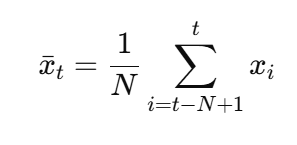

In [203]:
def moving_average(data, window_size=5):
    """
    Applies a moving average filter.
    """
    data = np.array(data)
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")

🧠 3. Statistical Summary
🔍 What it does:
Provides the key statistics from the cleaned and smoothed dataset.

In [204]:
from scipy.stats import t


def summarize_data(data, confidence=0.95):
    """
    Returns statistical summary of the data.
    """
    data = np.array(data)
    mean = np.mean(data)
    median = np.median(data)
    std = np.std(data)
    n = len(data)

    ci = (
        t.interval(confidence, df=n - 1, loc=mean, scale=std / np.sqrt(n))
        if n > 1
        else (mean, mean)
    )

    return {"mean": mean, "median": median, "std": std, "conf_interval": ci, "count": n}

🧠 4. Visualization
🔍 What it does:
Helps visually inspect the distribution of your estimates.

In [205]:
import matplotlib.pyplot as plt


def plot_histogram(data, title="Distribution", xlabel="Value"):
    """
    Plots histogram of the input data.
    """
    plt.figure(figsize=(8, 4))
    plt.hist(data, bins=20, color="skyblue", edgecolor="black")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

*Post processing test case*

Summary: {'mean': 44.49311562944379, 'median': 44.58976975814222, 'std': 2.1309138107126877, 'conf_interval': (44.05181587873253, 44.93441538015505), 'count': 92}


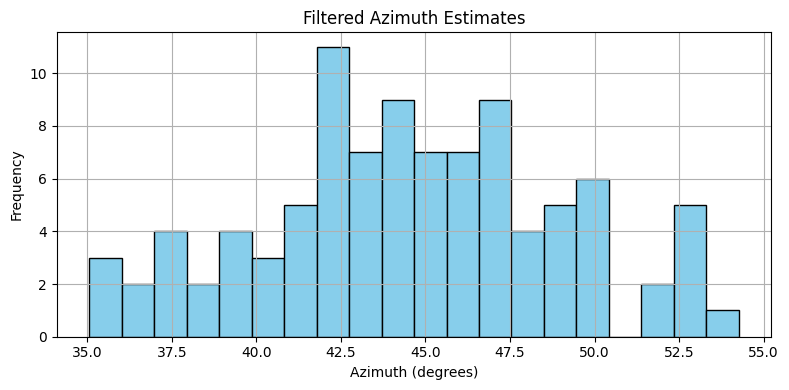

In [210]:
# Simulate noisy angle estimates around 45°, with outliers
np.random.seed(42)
true_angle = 45
noisy_angles = true_angle + np.random.randn(100) * 5
noisy_angles[[10, 25, 47]] = [120, -50, 130]  # Insert outliers

# Post-processing steps
filtered = remove_outliers_iqr(noisy_angles)
smoothed = moving_average(filtered, window_size=5)
summary = summarize_data(smoothed)

# Output
print("Summary:", summary)
plot_histogram(filtered, title="Filtered Azimuth Estimates", xlabel="Azimuth (degrees)")

*Put everything together*


--- Measurement Iteration 1 ---
IQ: 
[[1.2562134e+04+7.4167206e-33j 0.0000000e+00+7.3755383e-40j
  1.4693735e-39+0.0000000e+00j ... 0.0000000e+00+0.0000000e+00j
  0.0000000e+00+0.0000000e+00j 0.0000000e+00+0.0000000e+00j]
 [1.2562134e+04+7.4167206e-33j 0.0000000e+00+7.3755383e-40j
  1.4693735e-39+0.0000000e+00j ... 0.0000000e+00+0.0000000e+00j
  0.0000000e+00+0.0000000e+00j 0.0000000e+00+0.0000000e+00j]
 [1.2562134e+04+7.4167206e-33j 0.0000000e+00+7.3755383e-40j
  1.4693735e-39+0.0000000e+00j ... 0.0000000e+00+0.0000000e+00j
  0.0000000e+00+0.0000000e+00j 0.0000000e+00+0.0000000e+00j]
 [1.2562134e+04+7.4167206e-33j 0.0000000e+00+7.3755383e-40j
  1.4693735e-39+0.0000000e+00j ... 0.0000000e+00+0.0000000e+00j
  0.0000000e+00+0.0000000e+00j 0.0000000e+00+0.0000000e+00j]
 [1.2562134e+04+7.4167206e-33j 0.0000000e+00+7.3755383e-40j
  1.4693735e-39+0.0000000e+00j ... 0.0000000e+00+0.0000000e+00j
  0.0000000e+00+0.0000000e+00j 0.0000000e+00+0.0000000e+00j]]
Mean is: 
[[-156.04512-180.11432j]
 

C:\Users\anast\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\scipy\stats\_distn_infrastructure.py:2241: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
C:\Users\anast\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\scipy\stats\_distn_infrastructure.py:2242: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


Angle Estimates Summary: {'mean': -51.00000000000001, 'median': -51.00000000000001, 'std': 0.0, 'conf_interval': (nan, nan), 'count': 6}

Phase Distance Estimates (raw): [0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732, 0.8736762863954732]
Phase Distance Estimates Summary: {'mean': 0.8736762863954733, 'median': 0.8736762863954733, 'std': 0.0, 'conf_interval': (nan, nan), 'count': 6}

TDOA Distance Estimates (raw): [3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0, 3753450.0]
TDOA Distance Estimates Summary: {'mean': 3753450.0, 'median': 3753450.0, 'std': 0.0, 'conf_interval': (nan, nan), 'count': 6}


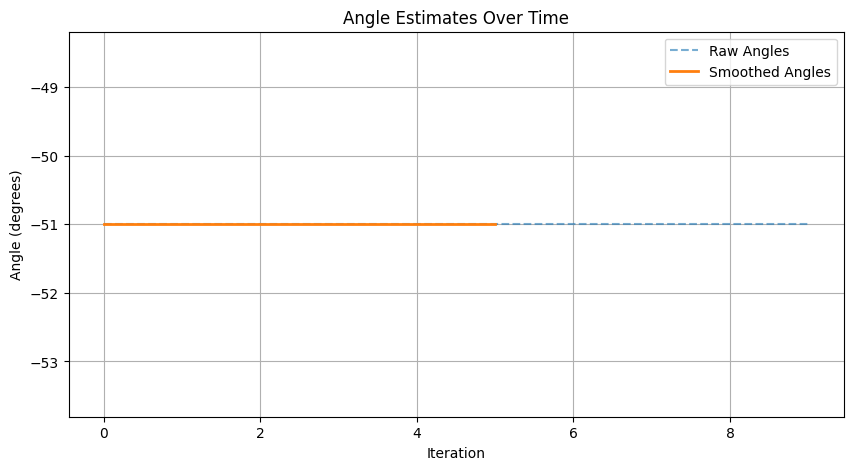

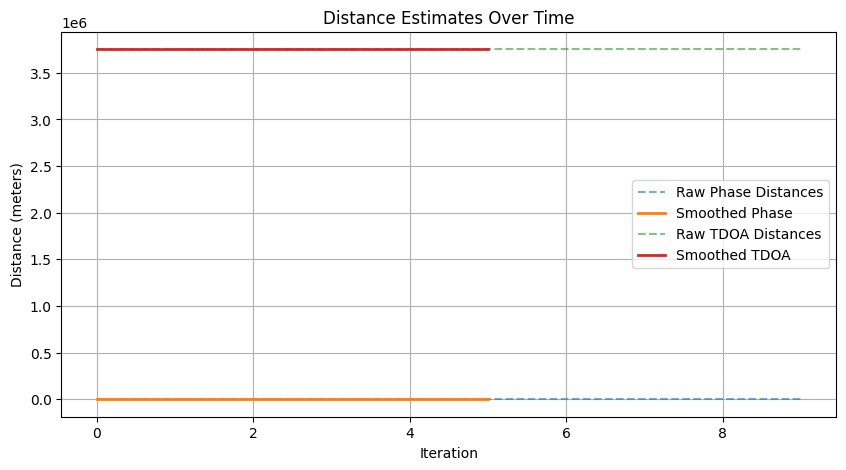

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t
from scipy.signal import correlate

# --- Preprocessing Functions ---


def load_iq_files(filenames):
    """
    Loads and aligns IQ data from multiple antennas.
    Returns a 2D array (num_antennas, num_samples).
    """
    iq_data_list = []
    min_len = None

    # Load and find minimum length
    for fname in filenames:
        iq = np.fromfile(fname, dtype=np.complex64)
        iq_data_list.append(iq)
        if min_len is None or len(iq) < min_len:
            min_len = len(iq)

    # Truncate all to the minimum length
    iq_data_list = [iq[:min_len] for iq in iq_data_list]

    # Stack into 2D array
    iq_matrix = np.vstack(iq_data_list)
    return iq_matrix


def sanitize_iq(iq_matrix):
    """
    Replace NaNs/Infs and clip extreme values before further processing.
    """
    # Replace NaN and Inf values with 0
    iq_matrix = np.nan_to_num(iq_matrix, nan=0.0, posinf=0.0, neginf=0.0)

    # Clip extreme values (optional)
    max_amp = 1e6  # or a value based on known SDR range
    too_large = np.abs(iq_matrix) > max_amp
    iq_matrix[too_large] = 0
    print("IQ: ")
    print(iq_matrix.astype(np.complex64))
    # Ensure consistent type
    return iq_matrix.astype(np.complex64)


def remove_dc_offset(iq_matrix):
    """
    Remove per-channel DC offset (mean).
    """
    iq_matrix = sanitize_iq(iq_matrix)
    means = np.mean(iq_matrix, axis=1, keepdims=True)
    print(means)
    print("DC offset: ")
    print(iq_matrix - means)
    return iq_matrix - means


def apply_window(iq_matrix):
    """
    Apply Hanning window to each antenna's IQ signal.
    """
    num_samples = iq_matrix.shape[1]
    window = np.hanning(num_samples)
    return iq_matrix * window


def apply_bandpass_filter(iq_matrix, lowcut, highcut, fs, order=5):
    """
    Apply bandpass Butterworth filter to each antenna signal.
    """

    def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        return butter(order, [low, high], btype="band")

    b, a = butter_bandpass(lowcut, highcut, fs, order)
    return np.array([lfilter(b, a, sig) for sig in iq_matrix])


def plot_iq_constellation(iq_matrix, num_samples=2000):
    """
    Plots the IQ constellation of all antennas in the complex plane.
    """
    plt.figure(figsize=(10, 6))
    for i in range(iq_matrix.shape[0]):
        iq = iq_matrix[i, :num_samples]
        plt.scatter(np.real(iq), np.imag(iq), s=1, alpha=0.5, label=f"Antenna {i+1}")
    plt.title("IQ Samples in Complex Plane")
    plt.xlabel("In-phase (I)")
    plt.ylabel("Quadrature (Q)")
    plt.legend()
    plt.axis("equal")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def preprocess_iq_data(iq_matrix, lowcut, highcut, fs):
    """
    Runs DC offset removal, windowing, and bandpass filtering in sequence.
    """
    iq_dc_removed = remove_dc_offset(iq_matrix)
    iq_windowed = apply_window(iq_dc_removed)
    # iq_filtered = apply_bandpass_filter(iq_windowed, lowcut, highcut, fs)
    return iq_windowed


# --- MUSIC functions---
def compute_covariance_matrix(iq_matrix):
    """
    Computes the covariance matrix from the MxN IQ data matrix.
    """
    return (iq_matrix @ iq_matrix.conj().T) / iq_matrix.shape[1]


def steering_vector(angle_rad, num_antennas, spacing, wavelength):
    """
    Constructs the steering vector for a given angle.
    """
    k = 2 * np.pi / wavelength
    positions = np.arange(num_antennas) * spacing
    return np.exp(-1j * k * positions * np.sin(angle_rad))


def music_spectrum(
    iq_matrix, num_sources, spacing, wavelength, angle_scan=np.linspace(-90, 90, 1801)
):
    """
    Computes the MUSIC spectrum over a range of angles.
    """
    R = compute_covariance_matrix(iq_matrix)
    eigvals, eigvecs = eig(R)

    # Sort eigenvalues descending
    idx = eigvals.argsort()[::-1]
    eigvecs = eigvecs[:, idx]

    # Noise subspace
    En = eigvecs[:, num_sources:]

    P_music = []
    for angle_deg in angle_scan:
        angle_rad = np.deg2rad(angle_deg)
        a = steering_vector(angle_rad, iq_matrix.shape[0], spacing, wavelength)
        music_val = 1 / np.abs(a.conj().T @ En @ En.conj().T @ a)
        P_music.append(music_val)

    return angle_scan, 10 * np.log10(np.real(P_music))  # dB scale


def run_music(
    iq_matrix, num_sources, spacing, wavelength, angle_scan=np.linspace(-90, 90, 1801)
):
    """
    Runs MUSIC algorithm to estimate directions of arrival.
    Returns angle array and MUSIC spectrum in dB.
    """
    angles, P_dB = music_spectrum(
        iq_matrix, num_sources, spacing, wavelength, angle_scan
    )
    return angles, P_dB


# --- Distance estimation functions---
def estimate_relative_distance(samples1, samples2, frequency_hz):
    """
    Estimate relative distance from phase difference between two antennas.

    Args:
        samples1, samples2: IQ samples from antennas 1 and 2 (complex arrays)
        frequency_hz: frequency of the signal in Hz (e.g., 100e6)

    Returns:
        delta_distance in meters
    """
    c = 3e8  # Speed of light
    wavelength = c / frequency_hz

    # Estimate phase difference
    phase1 = np.angle(np.mean(samples1))
    phase2 = np.angle(np.mean(samples2))

    phase_diff = np.angle(np.exp(1j * (phase2 - phase1)))  # Normalize to [-π, π]

    delta_distance = (wavelength / (2 * np.pi)) * phase_diff
    return delta_distance


def estimate_tdoa(signal1, signal2, fs):
    """
    Estimate the time delay between two signals using cross-correlation.
    :param signal1: Reference IQ signal
    :param signal2: Delayed IQ signal
    :param fs: Sampling frequency (Hz)
    :return: time_delay (seconds), sample_delay (samples)
    """
    corr = correlate(signal2, signal1, mode="full")
    lags = np.arange(-len(signal1) + 1, len(signal1))

    max_corr_index = np.argmax(np.abs(corr))
    sample_delay = lags[max_corr_index]
    time_delay = sample_delay / fs
    return time_delay, sample_delay


def estimate_average_distance(iq_matrix, frequency_hz):
    """
    Estimates relative distance for all unique antenna pairs,
    prints average absolute relative distance.
    """
    num_antennas = iq_matrix.shape[0]
    distances = []
    for i in range(num_antennas):
        for j in range(i + 1, num_antennas):
            delta_d = estimate_relative_distance(
                iq_matrix[i], iq_matrix[j], frequency_hz
            )
            distances.append(np.abs(delta_d))
            print(
                f"Relative distance between antenna {i+1} and {j+1}: {delta_d:.6f} meters"
            )
    avg_distance = np.mean(distances) if distances else 0
    print(
        f"Average absolute relative distance over all antenna pairs: {avg_distance:.6f} meters"
    )
    return avg_distance

# --- Post processing functions---
def remove_outliers_iqr(data, threshold=1.5):
    """
    Removes outliers using the IQR method.
    """
    data = np.array(data)
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1
    lower_bound = q1 - threshold * iqr
    upper_bound = q3 + threshold * iqr
    filtered_data = data[(data >= lower_bound) & (data <= upper_bound)]
    return filtered_data


def moving_average(data, window_size=5):
    """
    Applies a moving average filter.
    """
    data = np.array(data)
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")


def summarize_data(data, confidence=0.95):
    """
    Returns statistical summary of the data.
    """
    data = np.array(data)
    mean = np.mean(data)
    median = np.median(data)
    std = np.std(data)
    n = len(data)

    ci = (
        t.interval(confidence, df=n - 1, loc=mean, scale=std / np.sqrt(n))
        if n > 1
        else (mean, mean)
    )

    return {"mean": mean, "median": median, "std": std, "conf_interval": ci, "count": n}

# --- Multiple iterations function---
def run_batch_measurements(
    filenames,
    iterations=10,
    fs=2e6,
    frequency_hz=100e6,
    lowcut=10e3,
    highcut=1e6,
    num_sources=1,
    spacing=0.5,
    wavelength=1.0,
    angle_scan=np.linspace(-90, 90, 1801),
    post_window_size=5,
    outlier_threshold=1.5,
    visualize=True,
):
    angle_peaks = []
    distances_phase = []
    distances_tdoa = []

    for i in range(iterations):
        print(f"\n--- Measurement Iteration {i+1} ---")
        iq_matrix = load_iq_files(filenames)
        iq_processed = preprocess_iq_data(iq_matrix, lowcut, highcut, fs)

        # MUSIC angle estimation
        angles, P_dB = run_music(
            iq_processed, num_sources, spacing, wavelength, angle_scan
        )
        peak_angle = angles[np.argmax(P_dB)]
        angle_peaks.append(peak_angle)
        print(f"Estimated angle: {peak_angle:.2f}°")

        # Phase-based distance
        d_phase = estimate_average_distance(iq_processed, frequency_hz)
        distances_phase.append(d_phase)

        # TDOA-based distance using antenna pair 0 and 1 (as example)
        time_delay, sample_delay = estimate_tdoa(iq_processed[0], iq_processed[1], fs)
        d_tdoa = np.abs(time_delay * 3e8)
        distances_tdoa.append(d_tdoa)
        print(f"TDOA delay: {time_delay:.2e} s | Distance: {d_tdoa:.4f} m")

    # --- Post-processing ---
    def process_and_summarize(name, data):
        print(f"\n{name} (raw): {data}")
        filtered = remove_outliers_iqr(data, threshold=outlier_threshold)
        smoothed = moving_average(filtered, window_size=post_window_size)
        summary = summarize_data(smoothed)
        print(f"{name} Summary: {summary}")
        return smoothed, summary

    angles_smooth, angle_summary = process_and_summarize("Angle Estimates", angle_peaks)
    dist_phase_smooth, phase_summary = process_and_summarize(
        "Phase Distance Estimates", distances_phase
    )
    dist_tdoa_smooth, tdoa_summary = process_and_summarize(
        "TDOA Distance Estimates", distances_tdoa
    )

    # --- Optional Visualization ---
    if visualize:
        plt.figure(figsize=(10, 5))
        plt.plot(angle_peaks, label="Raw Angles", linestyle="--", alpha=0.6)
        plt.plot(
            range(len(angles_smooth)),
            angles_smooth,
            label="Smoothed Angles",
            linewidth=2,
        )
        plt.title("Angle Estimates Over Time")
        plt.xlabel("Iteration")
        plt.ylabel("Angle (degrees)")
        plt.legend()
        plt.grid(True)
        plt.show()

        plt.figure(figsize=(10, 5))
        plt.plot(
            distances_phase, label="Raw Phase Distances", linestyle="--", alpha=0.6
        )
        plt.plot(
            range(len(dist_phase_smooth)),
            dist_phase_smooth,
            label="Smoothed Phase",
            linewidth=2,
        )
        plt.plot(distances_tdoa, label="Raw TDOA Distances", linestyle="--", alpha=0.6)
        plt.plot(
            range(len(dist_tdoa_smooth)),
            dist_tdoa_smooth,
            label="Smoothed TDOA",
            linewidth=2,
        )
        plt.title("Distance Estimates Over Time")
        plt.xlabel("Iteration")
        plt.ylabel("Distance (meters)")
        plt.legend()
        plt.grid(True)
        plt.show()

    return {
        "angles_raw": angle_peaks,
        "angles_smoothed": angles_smooth,
        "angle_summary": angle_summary,
        "distances_phase_raw": distances_phase,
        "distances_phase_smoothed": dist_phase_smooth,
        "phase_summary": phase_summary,
        "distances_tdoa_raw": distances_tdoa,
        "distances_tdoa_smoothed": dist_tdoa_smooth,
        "tdoa_summary": tdoa_summary,
    }


# # --- Parameters ---
# lowcut = 10e3
# highcut = 1e6
# fs = 2e6
# frequency_hz = 100e6
# num_sources = 1
# spacing = 0.5
# wavelength = 1.0
# angle_scan = np.linspace(-90, 90, 1801)

# --- Load data ---
filenames = [f"IQ_{i+1}.iq" for i in range(5)]
results = run_batch_measurements(filenames)

# # --- Preprocessing ---
# iq_processed = preprocess_iq_data(iq_matrix, lowcut, highcut, fs)

# # --- Visualization ---
# plot_iq_constellation(iq_processed)

# # --- MUSIC ---
# angles, P_dB = run_music(iq_processed, num_sources, spacing, wavelength, angle_scan)
# plt.figure(figsize=(10, 6))
# plt.plot(angles, P_dB)
# plt.title("MUSIC Spectrum - Estimated DoA")
# plt.xlabel("Angle (degrees)")
# plt.ylabel("Spectrum Power (dB)")
# plt.grid(True)
# plt.tight_layout()
# plt.show()

# # --- Distance Estimation ---
# estimate_average_distance(iq_processed, frequency_hz)